In [10]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
jam = rng.uniform(1, 9, size=60)
nilai = 35 + 5 * jam + rng.normal(
    loc=0, scale=6, size=60)
df = pd.DataFrame({"jam_belajar": jam,
                   "nilai_ujian": nilai})

In [6]:
df.head()

,jam_belajar,nilai_ujian
0,7.191648,65.763255
1,4.511028,63.364808
2,7.868783,64.246698
3,6.578944,65.885411
4,1.753419,44.743612


In [7]:
df.shape

(60, 2)

In [8]:

df.isna().sum()

,0
jam_belajar,0
nilai_ujian,0


In [9]:

df.describe()

,jam_belajar,nilai_ujian
count,60.000000,60.000000
mean,5.158475,59.549841
std,2.268995,12.131672
min,1.058898,29.930568
25%,3.184446,50.334266
50%,5.121159,60.134906
75%,7.200503,67.910802
max,8.804979,82.542228


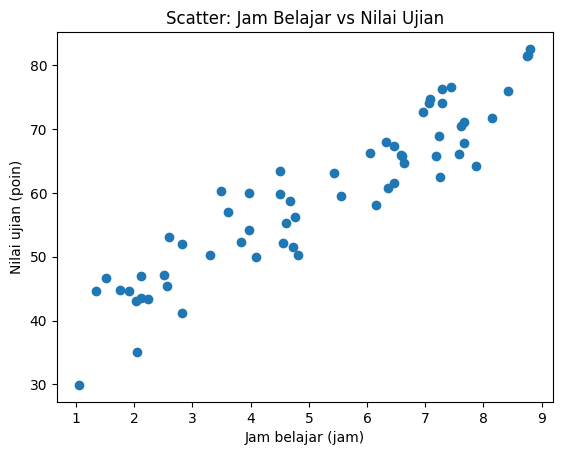

In [13]:
import matplotlib.pyplot as plt

plt.scatter(df['jam_belajar'],
            df['nilai_ujian'])
plt.xlabel('Jam belajar (jam)')
plt.ylabel('Nilai ujian (poin)')
plt.title('Scatter: Jam Belajar vs Nilai Ujian')
plt.show()

In [24]:
from sklearn.linear_model import LinearRegression

X = df[["jam_belajar"]]
y = df["nilai_ujian"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [26]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [27]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])
print(f"Model Colab: nilai_prediksi = "
      f"{b0:.3f} + ({b1:.3f}) × jam_belajar")

Model Colab: nilai_prediksi = 34.841 + (4.839) × jam_belajar


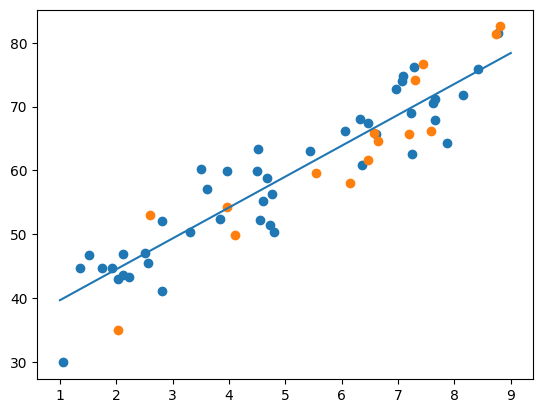

In [28]:
x_grid = pd.DataFrame(
    {"jam_belajar": np.linspace(1, 9, 100)})
y_grid = model.predict(x_grid)
plt.scatter(X_train["jam_belajar"], y_train)
plt.scatter(X_test["jam_belajar"], y_test)
plt.plot(x_grid["jam_belajar"], y_grid)
plt.show()

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_test = model.predict(X_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(
    mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 4.323764956409487
RMSE: 4.884253621661415
R2  : 0.8388802621811073
